# Mental disorders, daily-life interference, and reported care

Judy Chen

## Setup

In [1]:
from pathlib import Path
import csv
import io
import os
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import PathPatch, Rectangle, Patch
from matplotlib.path import Path as MplPath
from matplotlib.ticker import PercentFormatter

candidates = [
    Path.cwd(),
    Path.cwd() / "milestone2_draft",
    Path.cwd() / "static-viz-project" / "milestone2_draft",
]
DRAFT_DIR = next(
    (path for path in candidates if (path / "static-draft.ipynb").is_file()),
    None,
)
if DRAFT_DIR is None:
    raise FileNotFoundError("Open this notebook from the course repository or its draft folder.")

DATA_DIR = Path(os.environ.get("MENTAL_HEALTH_DATA_DIR", DRAFT_DIR / "data")).expanduser()
CPES_PATH = Path(os.environ.get("CPES_DATA_PATH", DATA_DIR / "20240-0001-Data.dta")).expanduser()
NSDUH_PATH = Path(os.environ.get("NSDUH_DATA_PATH", DATA_DIR / "nsduh2024.zip")).expanduser()
FIGURE_DIR = DRAFT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

missing_files = [path.name for path in (CPES_PATH, NSDUH_PATH) if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Missing local survey files: " + ", ".join(missing_files)
        + ". Follow the data setup in README.md. Raw data are intentionally absent from GitHub."
    )

BG, INK, MUTED = "#FAF7F1", "#25343C", "#5F6B70"
TEAL, GOLD, GRID = "#247C78", "#C78D36", "#DCDCD4"
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "savefig.facecolor": BG,
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "svg.fonttype": "none",
})

def finish_figure(fig, filename, source_note):
    """Save a named, aggregate-only figure and show the same figure in the notebook."""
    fig.text(0.02, 0.02, source_note, fontsize=8.5, color=MUTED, va="bottom")
    fig.savefig(FIGURE_DIR / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

DISORDER_LABELS = ["Depression", "Generalized anxiety", "Panic disorder", "Social phobia",
                   "Agoraphobia*", "PTSD"]
CARE_COLORS = {"Both": TEAL, "Professional contact only": "#78AEA7",
               "Medication only": "#657F9B", "Neither reported": GOLD}
SCORE_CMAP = LinearSegmentedColormap.from_list("interference", ["#EFF1E8", "#99C3B9", TEAL])
CPES_SOURCE = "CPES 2001–2003 · NCS-R Part 2 + NLAAS · ICPSR 20240"
NSDUH_SOURCE = "NSDUH 2024 · Adults with a past-year major depressive episode · SAMHSA"

def figure_title(fig, title, subtitle=""):
    fig.text(0.03, 0.96, title, fontsize=17, weight="bold", va="top")
    if subtitle:
        fig.text(0.03, 0.905, subtitle, fontsize=11, color=MUTED, va="top")

def percentage_axis(ax, axis="x"):
    getattr(ax, axis + "axis").set_major_formatter(PercentFormatter(100, decimals=0))

def clean_axis(ax, grid_axis="x"):
    ax.tick_params(length=0)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)


In [2]:
DISORDERS = {
    "Major depressive disorder": {
        "diagnosis": "V07655", "social": "V00992",
        "domains": ["V00989", "V00991", "V00992"],
        "professional_care": "V01013", "ever_help": "V00995",
    },
    "Generalized anxiety disorder": {
        "diagnosis": "V07613", "social": "V01870",
        "domains": ["V01867", "V01869", "V01870"],
        "professional_care": "V01891", "ever_help": "V01874",
    },
    "Panic disorder": {
        "diagnosis": "V07716", "social": "V01353",
        "domains": ["V01350", "V01352", "V01353"],
        "professional_care": "V01394", "ever_help": "V01357",
    },
    "Social phobia": {
        "diagnosis": "V07748", "social": "V01579",
        "domains": ["V01576", "V01578", "V01579"],
        "professional_care": "V01621", "ever_help": "V01583",
    },
    "Agoraphobia without panic disorder": {
        "diagnosis": "V07513", "social": "V01692",
        "domains": ["V01689", "V01691", "V01692"],
        "professional_care": "V01734", "ever_help": "V01697",
    },
    "PTSD": {
        "diagnosis": "V07725", "social": "V04037",
        "domains": ["V04034", "V04036", "V04037"],
        "professional_care": "V04040", "ever_help": None,
    },
}
MEDICATIONS = {
    "Antidepressants": "V02614", "Tranquilizers": "V02616",
    "Stimulants": "V02617", "Antipsychotics": "V02620",
    "Sleeping pills/sedatives": "V02807",
}
cpes_columns = {"CPESCASE", "CPESPROJ", "NCNLWTLG", "SESTRAT", "SECLUSTR"}
for spec in DISORDERS.values():
    cpes_columns.update([
        spec["diagnosis"], spec["social"], spec["professional_care"], spec["ever_help"],
        *spec["domains"],
    ])
cpes_columns.discard(None)
cpes_columns.update(MEDICATIONS.values())

with pd.io.stata.StataReader(CPES_PATH, convert_categoricals=False) as reader:
    cpes_labels = reader.variable_labels()
    cpes_source_rows = int(reader._nobs)
    cpes_source_columns = len(cpes_labels)
cpes_raw = pd.read_stata(CPES_PATH, columns=sorted(cpes_columns), convert_categoricals=False)
cpes = cpes_raw.loc[cpes_raw["NCNLWTLG"].gt(0)].copy()
assert cpes_source_rows == 20_013 and cpes_source_columns == 5_543
assert cpes_raw["CPESCASE"].nunique() == 20_013 and len(cpes) == 10_341

nsduh_columns = [
    "IRAMDEYR", "IRAMDEIMP", "ATXMDEYR", "ARXMDEYR", "AMDETXRX",
    "ANALWT2_C", "VESTR_C", "VEREP", "IRINSUR4", "AGE3", "INCOME", "POVERTY3",
]
with zipfile.ZipFile(NSDUH_PATH) as archive:
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_source_columns = len(next(csv.reader(io.TextIOWrapper(stream), delimiter="\t")))
    with archive.open("NSDUH_2024_Tab.txt") as stream:
        nsduh_raw = pd.read_csv(stream, sep="\t", usecols=nsduh_columns, na_values=["."])
assert len(nsduh_raw) == 58_633 and nsduh_source_columns == 2_632
nsduh_adults = nsduh_raw.loc[nsduh_raw["IRAMDEYR"].isin([0, 1])].copy()
nsduh_mde = nsduh_adults.loc[nsduh_adults["IRAMDEYR"].eq(1)].copy()
care_known = nsduh_mde["ATXMDEYR"].isin([0, 1]) & nsduh_mde["ARXMDEYR"].isin([0, 1])
nsduh_care = nsduh_mde.loc[care_known].copy()
nsduh_care["care_group"] = np.select([
    nsduh_care["ATXMDEYR"].eq(1) & nsduh_care["ARXMDEYR"].eq(1),
    nsduh_care["ATXMDEYR"].eq(1),
    nsduh_care["ARXMDEYR"].eq(1),
], ["Both", "Professional contact only", "Medication only"], default="Neither reported")
nsduh_care["reported_either"] = nsduh_care["ATXMDEYR"].eq(1) | nsduh_care["ARXMDEYR"].eq(1)
assert len(nsduh_adults) == 47_299 and len(nsduh_mde) == 5_205
assert len(nsduh_care) == 5_008 and (~care_known).sum() == 197


care_values = {}
care_coverage = []
for name, spec in DISORDERS.items():
    observed = cpes[spec["professional_care"]]
    care = observed.map({1: 1.0, 5: 0.0})
    inferred_no = pd.Series(False, index=cpes.index)
    if spec["ever_help"] is not None:
        never_help = cpes[spec["ever_help"]].eq(5)
        assert not (never_help & observed.eq(1)).any()
        # An explicit lifetime "no" rules out past-year help for this disorder.
        inferred_no = observed.isna() & never_help
        care = care.mask(inferred_no, 0.0)
    # PTSD's lifetime item concerns a selected event: do not infer from it.
    care_values[name] = care
    cases = cpes[spec["diagnosis"]].eq(1)
    care_coverage.append({"name": name, "cases": int(cases.sum()),
                          "known": int((cases & care.notna()).sum()),
                          "inferred_no": int((cases & inferred_no).sum())})
assert [r["known"] for r in care_coverage] == [916, 496, 353, 849, 220, 257]


In [3]:
def survey_mean(frame, values, domain=None, *, weight, strata, cluster):
    """Estimate a domain mean/ratio and its design-based standard error."""
    y = pd.Series(values, index=frame.index, dtype=float)
    active = y.notna()
    if domain is not None:
        active &= pd.Series(domain, index=frame.index).fillna(False).astype(bool)
    w = frame[weight].astype(float)
    if not np.isfinite(w).all() or not w.gt(0).all():
        raise ValueError("Use a full analysis pool with finite, positive survey weights.")
    if frame[[strata, cluster]].isna().any().any():
        raise ValueError("Missing survey design identifiers need investigation.")
    denominator = w.loc[active].sum()
    if denominator <= 0:
        raise ValueError("No valid weighted observations in the requested domain.")
    estimate = float(np.average(y.loc[active], weights=w.loc[active]))
    residual = (y - estimate).where(active, 0.0)
    design = frame[[strata, cluster]].copy()
    design["linearized"] = w * residual / denominator
    psu_totals = design.groupby([strata, cluster], observed=True)["linearized"].sum()
    components = psu_totals.groupby(level=0).agg(["count", "sum"])
    if components["count"].lt(2).any():
        raise ValueError("A single-PSU stratum needs a documented variance treatment.")
    centered = psu_totals - psu_totals.groupby(level=0).transform("mean")
    square_sums = centered.pow(2).groupby(level=0).sum()
    m = components["count"]
    variance = float((m / (m - 1) * square_sums).sum())
    se = float(np.sqrt(max(variance, 0)))
    degrees_freedom = int((m - 1).sum())
    critical = float(t.ppf(0.975, degrees_freedom))
    return {
        "estimate": estimate, "se": se,
        "lower": estimate - critical * se, "upper": estimate + critical * se,
        "n": int(active.sum()), "design_df": degrees_freedom,
    }

CPES_DESIGN = {"weight": "NCNLWTLG", "strata": "SESTRAT", "cluster": "SECLUSTR"}
NSDUH_DESIGN = {"weight": "ANALWT2_C", "strata": "VESTR_C", "cluster": "VEREP"}


## Figure 01 · Past-year prevalence

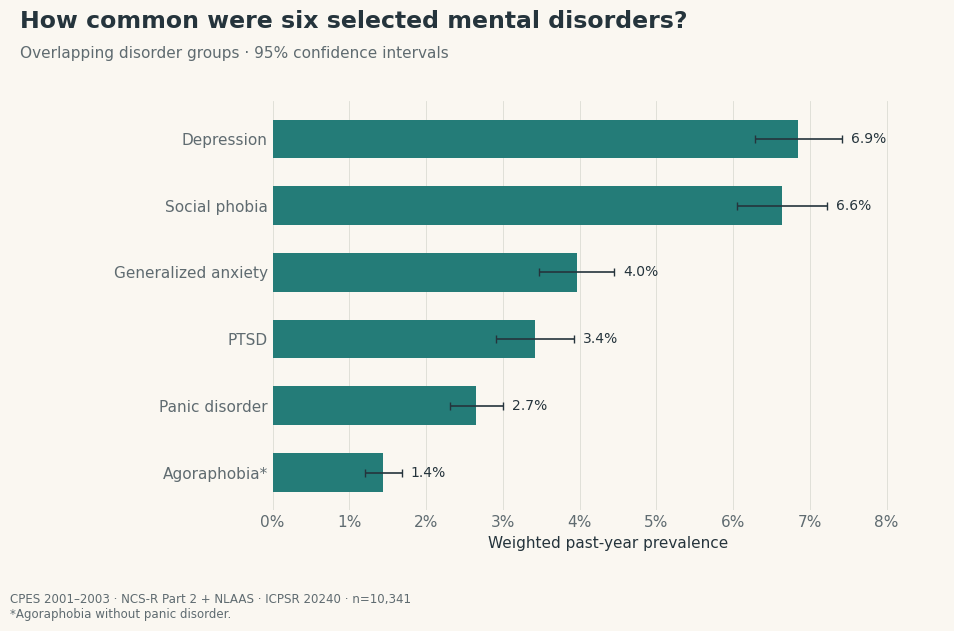

In [4]:
prevalence = pd.DataFrame([
    {"name": label, **survey_mean(cpes, cpes[spec["diagnosis"]].map({1: 1., 5: 0.}), **CPES_DESIGN)}
    for label, spec in zip(DISORDER_LABELS, DISORDERS.values())
]).sort_values("estimate")
fig, ax = plt.subplots(figsize=(10.5, 6.5))
fig.subplots_adjust(left=0.27, right=0.91, top=0.82, bottom=0.19)
y = np.arange(6)
point = prevalence["estimate"].to_numpy() * 100
low = prevalence["lower"].clip(0).to_numpy() * 100
high = prevalence["upper"].clip(upper=1).to_numpy() * 100
ax.barh(y, point, color=TEAL, height=0.58)
ax.errorbar(point, y, xerr=[point-low, high-point], fmt="none", ecolor=INK, capsize=3, lw=1.2)
ax.set_yticks(y, prevalence["name"])
ax.set_xlim(0, high.max()*1.18)
ax.set_xlabel("Weighted past-year prevalence")
for yy, value, upper in zip(y, point, high):
    ax.text(upper+0.12, yy, f"{value:.1f}%", va="center", fontsize=10)
percentage_axis(ax)
clean_axis(ax)
figure_title(fig, "How common were six selected mental disorders?", "Overlapping disorder groups · 95% confidence intervals")
finish_figure(fig, "01_prevalence.png", CPES_SOURCE + " · n=10,341\n*Agoraphobia without panic disorder.")


## Figure 02 · Pairwise co-occurrence

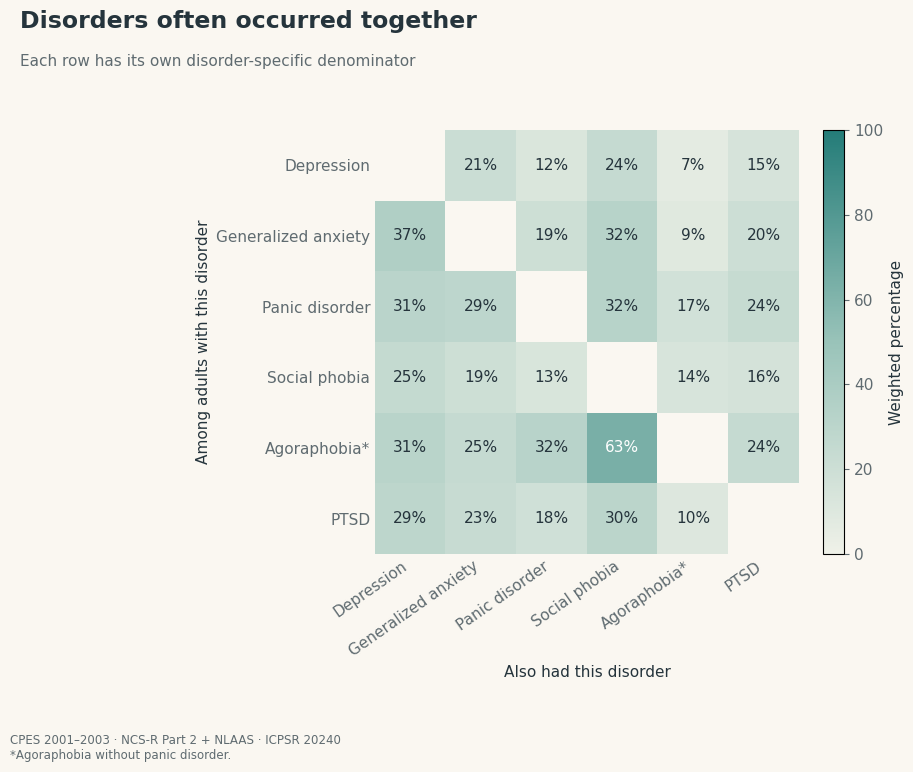

In [5]:
diagnosis_columns = [spec["diagnosis"] for spec in DISORDERS.values()]
assert cpes[diagnosis_columns].isin([1, 5]).all().all()
flags = cpes[diagnosis_columns].eq(1).to_numpy()
weights = cpes["NCNLWTLG"].to_numpy()
cooccurrence = np.full((6, 6), np.nan)
for row in range(6):
    for col in range(6):
        if row != col:
            cooccurrence[row, col] = np.average(flags[flags[:, row], col], weights=weights[flags[:, row]])*100
fig, ax = plt.subplots(figsize=(10, 8))
fig.subplots_adjust(left=0.26, right=0.86, bottom=0.28, top=0.81)
image = ax.imshow(cooccurrence, cmap=SCORE_CMAP, vmin=0, vmax=100)
for row in range(6):
    for col in range(6):
        if row != col:
            value = cooccurrence[row, col]
            ax.text(col, row, f"{value:.0f}%", ha="center", va="center",
                    color="white" if value>60 else INK)
ax.set_xticks(range(6), DISORDER_LABELS, rotation=35, ha="right")
ax.set_yticks(range(6), DISORDER_LABELS)
ax.set_xlabel("Also had this disorder")
ax.set_ylabel("Among adults with this disorder")
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, fraction=.045, pad=.04, label="Weighted percentage")
figure_title(fig, "Disorders often occurred together", "Each row has its own disorder-specific denominator")
finish_figure(fig, "02_cooccurrence_heatmap.png", CPES_SOURCE + "\n*Agoraphobia without panic disorder.")


## Figure 03 · Comorbid disorder combinations

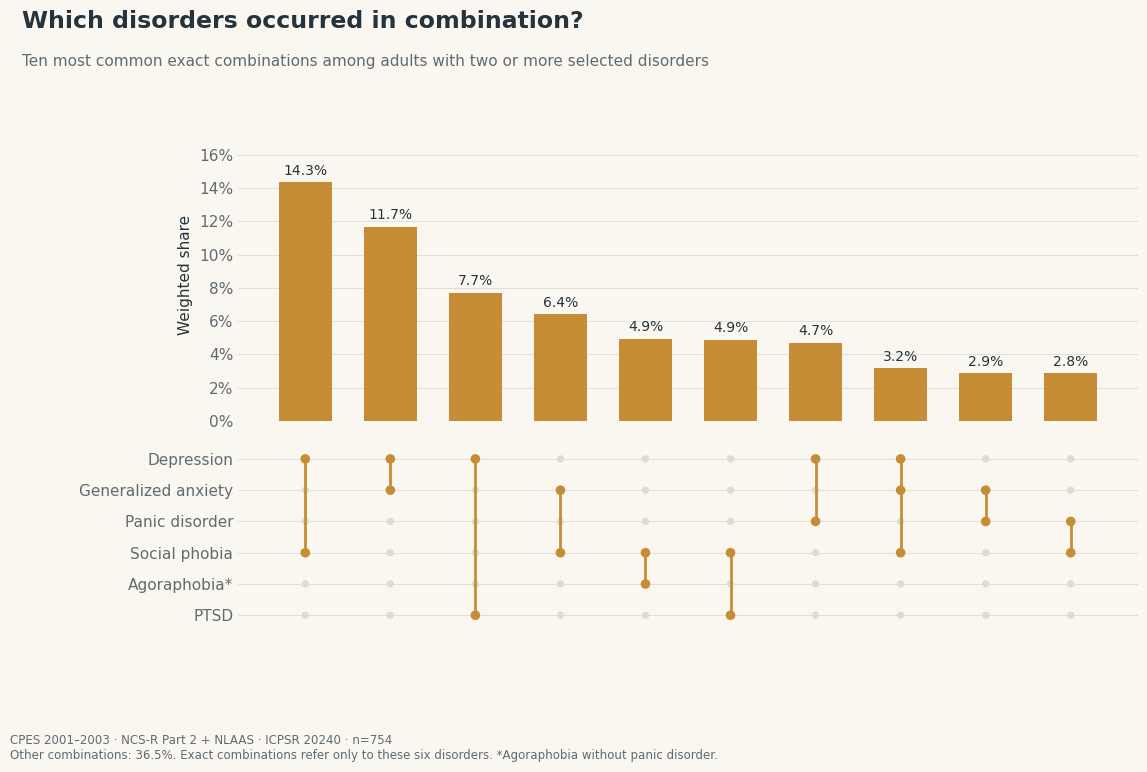

In [6]:
bits = flags.astype(int)
patterns = (bits * (2**np.arange(6))).sum(axis=1)
disorder_count = bits.sum(axis=1)
multi = disorder_count >= 2
pattern_weights = pd.DataFrame({"pattern": patterns[multi], "weight": weights[multi]}).groupby("pattern")["weight"].sum()
shares = pattern_weights.sort_values(ascending=False).head(10) / pattern_weights.sum()*100
assert all(int(p).bit_count() >= 2 for p in shares.index)
omitted_share = 100-shares.sum()
fig = plt.figure(figsize=(12, 8))
grid = fig.add_gridspec(2, 1, left=.21, right=.96, top=.81, bottom=.18,
                        height_ratios=[1.5, 1], hspace=.08)
ax = fig.add_subplot(grid[0])
matrix = fig.add_subplot(grid[1], sharex=ax)
x = np.arange(len(shares))
ax.bar(x, shares, color=GOLD, width=.62)
ax.set_ylim(0, shares.max()*1.22)
ax.set_ylabel("Weighted share")
percentage_axis(ax, "y")
clean_axis(ax, "y")
ax.tick_params(axis="x", bottom=False, labelbottom=False)
for xx, value in zip(x, shares):
    ax.text(xx, value+.45, f"{value:.1f}%", ha="center", fontsize=10)
for row in range(6):
    matrix.axhline(row, color=GRID, lw=.6, zorder=0)
    matrix.scatter(x, np.repeat(row, len(x)), color="#DADDD6", s=28, edgecolors="none")
for col, pattern in enumerate(shares.index):
    active = [row for row in range(6) if int(pattern) & (2**row)]
    matrix.plot([col, col], [min(active), max(active)], color=GOLD, lw=2)
    matrix.scatter(np.repeat(col, len(active)), active, color=GOLD, s=48, edgecolors="none", zorder=3)
matrix.set_yticks(range(6), DISORDER_LABELS)
matrix.set_ylim(5.6, -.6)
matrix.set_xticks([])
matrix.tick_params(length=0)
figure_title(fig, "Which disorders occurred in combination?", "Ten most common exact combinations among adults with two or more selected disorders")
finish_figure(fig, "03_upset.png", CPES_SOURCE + f" · n={multi.sum():,}\nOther combinations: {omitted_share:.1f}%. Exact combinations refer only to these six disorders. *Agoraphobia without panic disorder.")


## Figure 04 · Social-life interference distributions

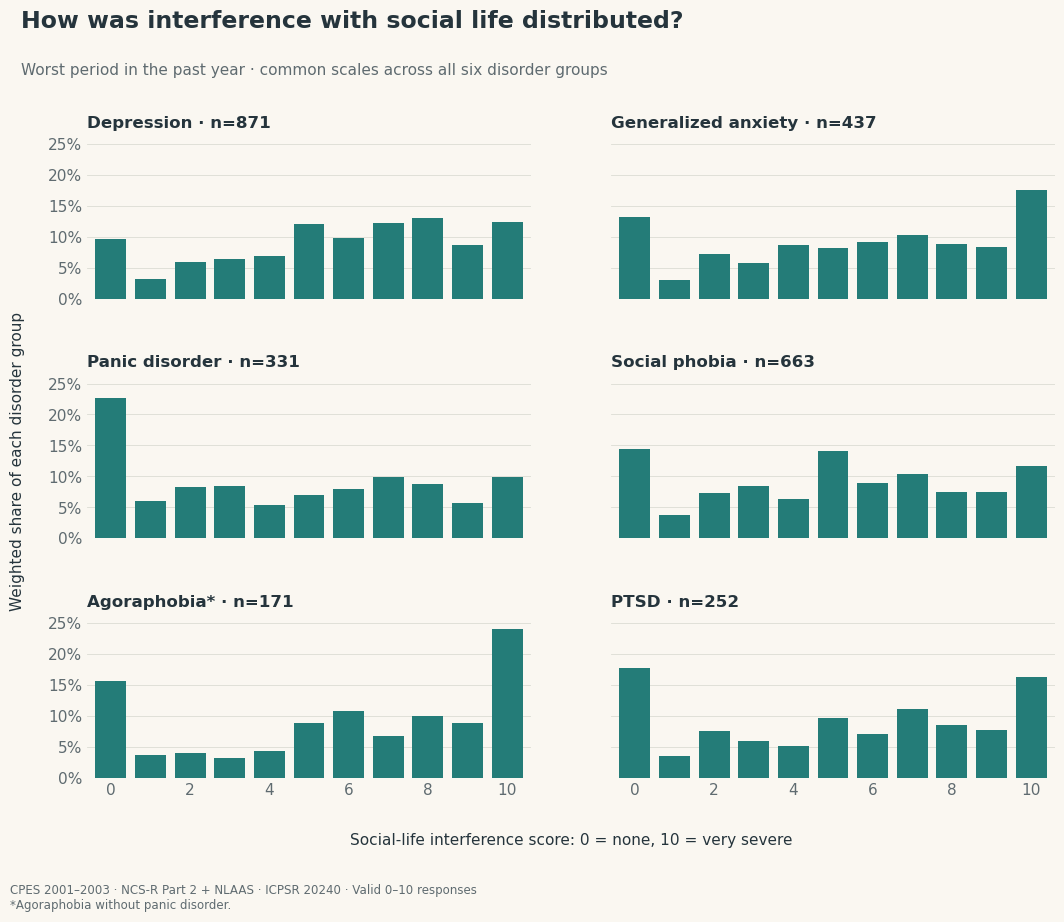

In [7]:
score_distributions, score_counts = [], []
for spec in DISORDERS.values():
    valid = cpes[spec["diagnosis"]].eq(1) & cpes[spec["social"]].between(0, 10)
    counts = cpes.loc[valid].groupby(spec["social"])["NCNLWTLG"].sum().reindex(range(11), fill_value=0)
    score_distributions.append(counts / counts.sum()*100)
    score_counts.append(int(valid.sum()))
max_height = np.ceil(max(row.max() for row in score_distributions)/5)*5
fig, axes = plt.subplots(3, 2, figsize=(11, 9.6), sharex=True, sharey=True)
fig.subplots_adjust(left=.09, right=.97, bottom=.16, top=.82, hspace=.55, wspace=.18)
for ax, label, distribution, n in zip(axes.flat, DISORDER_LABELS, score_distributions, score_counts):
    ax.bar(range(11), distribution, width=.78, color=TEAL)
    ax.set_title(f"{label} · n={n:,}", fontsize=12, loc="left", pad=12)
    ax.set_xlim(-.6, 10.6)
    ax.set_ylim(0, max_height)
    ax.set_xticks([0, 2, 4, 6, 8, 10])
    percentage_axis(ax, "y")
    clean_axis(ax, "y")
fig.text(.02, .49, "Weighted share of each disorder group", rotation=90, va="center", fontsize=11)
fig.text(.53, .09, "Social-life interference score: 0 = none, 10 = very severe", ha="center", fontsize=11)
figure_title(fig, "How was interference with social life distributed?", "Worst period in the past year · common scales across all six disorder groups")
finish_figure(fig, "04_social_interference_distributions.png", CPES_SOURCE + " · Valid 0–10 responses\n*Agoraphobia without panic disorder.")


## Figure 05 · Daily-life domains

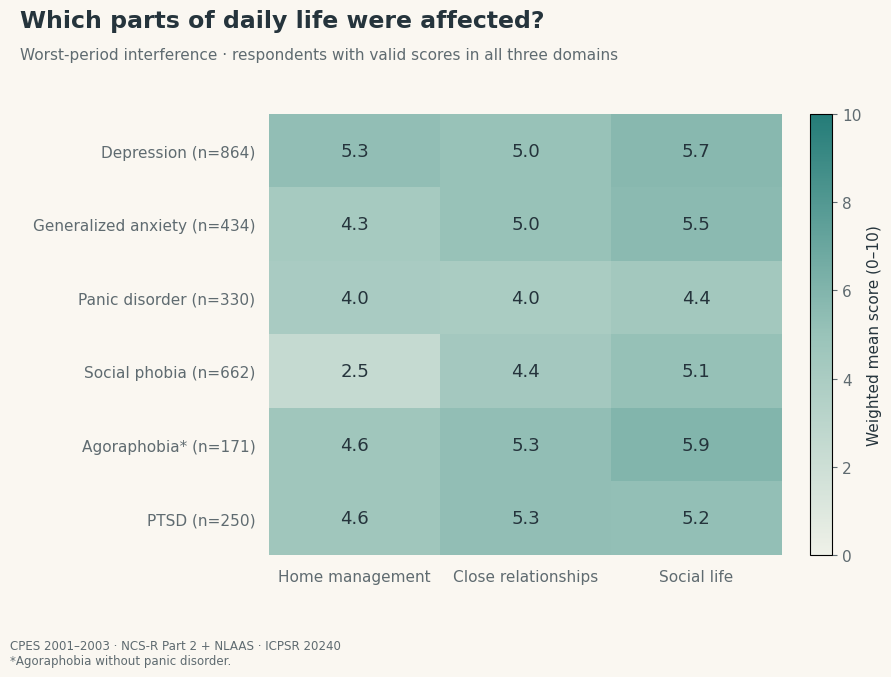

In [8]:
domain_means, complete_counts = [], []
for spec in DISORDERS.values():
    valid = cpes[spec["diagnosis"]].eq(1) & cpes[spec["domains"]].apply(lambda s: s.between(0,10)).all(axis=1)
    domain_means.append([np.average(cpes.loc[valid, v], weights=cpes.loc[valid,"NCNLWTLG"]) for v in spec["domains"]])
    complete_counts.append(int(valid.sum()))
assert complete_counts == [864, 434, 330, 662, 171, 250]
fig, ax = plt.subplots(figsize=(9.6, 7))
fig.subplots_adjust(left=.29, right=.88, bottom=.18, top=.81)
image = ax.imshow(domain_means, cmap=SCORE_CMAP, vmin=0, vmax=10, aspect="auto")
for row in range(6):
    for col in range(3):
        value = domain_means[row][col]
        ax.text(col, row, f"{value:.1f}", ha="center", va="center", color="white" if value>6.4 else INK, fontsize=13)
ax.set_xticks(range(3), ["Home management", "Close relationships", "Social life"])
ax.set_yticks(range(6), [f"{label} (n={n:,})" for label,n in zip(DISORDER_LABELS, complete_counts)])
ax.tick_params(length=0, pad=10)
fig.colorbar(image, ax=ax, fraction=.045, pad=.05, label="Weighted mean score (0–10)")
figure_title(fig, "Which parts of daily life were affected?", "Worst-period interference · respondents with valid scores in all three domains")
finish_figure(fig, "05_daily_life_domains.png", CPES_SOURCE + "\n*Agoraphobia without panic disorder.")


## Figure 06 · Disorder-specific professional care

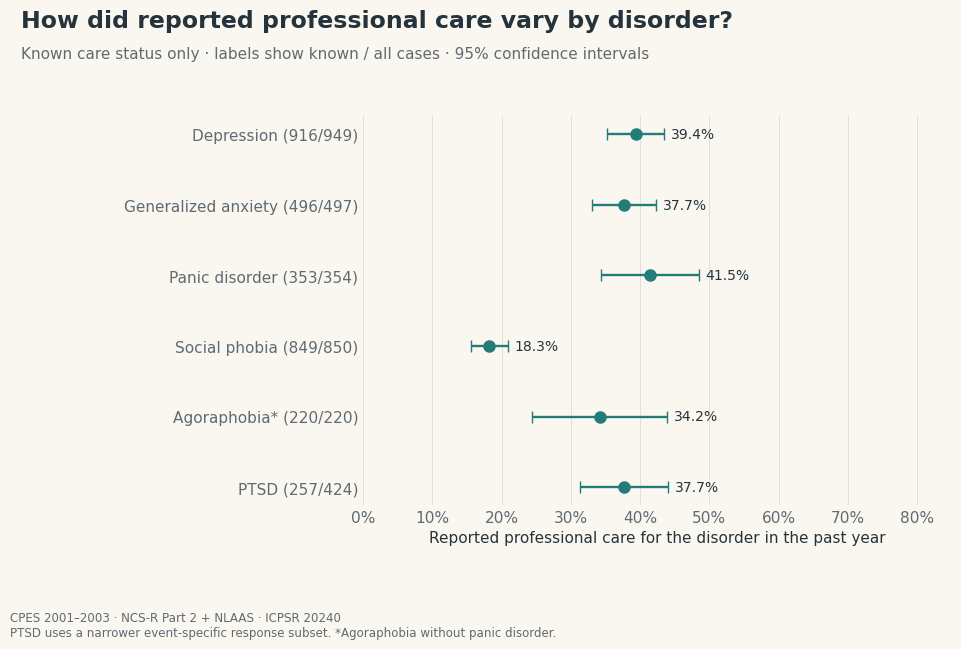

In [9]:
care_rows = []
for label, (name, spec), coverage in zip(DISORDER_LABELS, DISORDERS.items(), care_coverage):
    cases = cpes[spec["diagnosis"]].eq(1)
    result = survey_mean(cpes, care_values[name], cases, **CPES_DESIGN)
    care_rows.append({"label": label, "case_n": coverage["cases"], **result})
professional_care = pd.DataFrame(care_rows)
fig, ax = plt.subplots(figsize=(10.7, 6.7))
fig.subplots_adjust(left=.35, right=.90, bottom=.22, top=.80)
y = np.arange(6)
point = professional_care["estimate"].to_numpy()*100
low = professional_care["lower"].clip(0).to_numpy()*100
high = professional_care["upper"].clip(upper=1).to_numpy()*100
ax.errorbar(point, y, xerr=[point-low, high-point], fmt="o", color=TEAL, ecolor=TEAL, capsize=4, ms=8, lw=1.7)
ax.set_yticks(y, [f"{r.label} ({r.n}/{r.case_n})" for r in professional_care.itertuples()])
ax.invert_yaxis()
ax.set_xlim(0, 85)
ax.set_xlabel("Reported professional care for the disorder in the past year")
for yy, p, upper in zip(y, point, high):
    ax.text(upper+1, yy, f"{p:.1f}%", va="center", fontsize=10)
percentage_axis(ax)
clean_axis(ax)
figure_title(fig, "How did reported professional care vary by disorder?", "Known care status only · labels show known / all cases · 95% confidence intervals")
finish_figure(fig, "06_professional_care.png", CPES_SOURCE + "\nPTSD uses a narrower event-specific response subset. *Agoraphobia without panic disorder.")


## Figure 07 · Medication classes

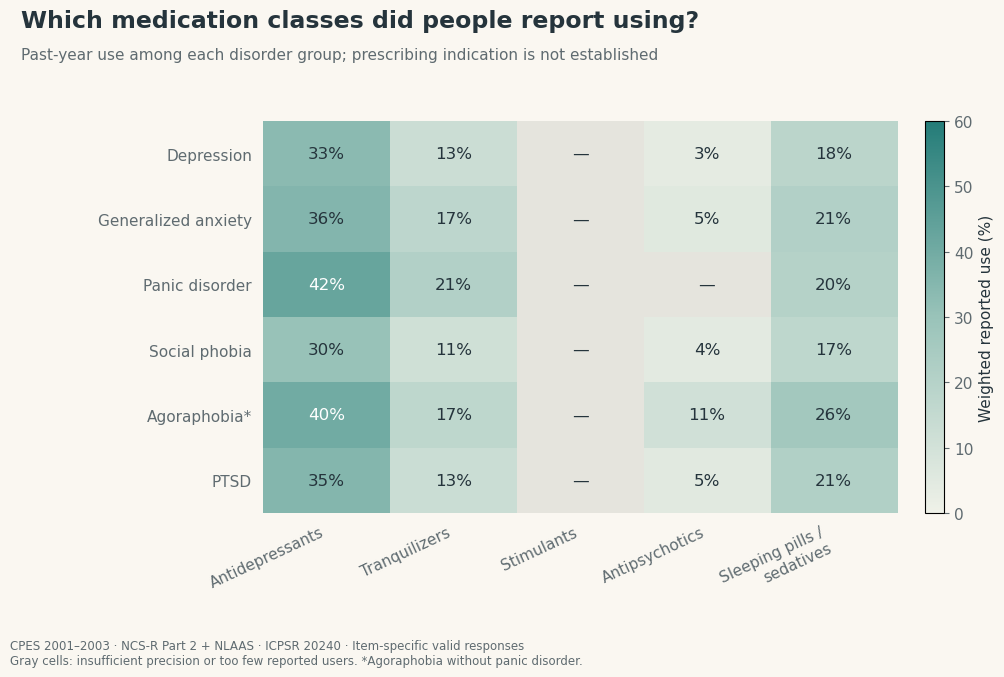

In [10]:
medication_rates = np.full((6, 5), np.nan)
medication_audit = []
for row, (name, spec) in enumerate(DISORDERS.items()):
    cases = cpes[spec["diagnosis"]].eq(1)
    for col, (medication, variable) in enumerate(MEDICATIONS.items()):
        values = cpes[variable].map({1: 1., 5: 0.})
        result = survey_mean(cpes, values, cases, **CPES_DESIGN)
        yes_n = int((cases & values.eq(1)).sum())
        no_n = int((cases & values.eq(0)).sum())
        reliable = result["n"]>=50 and min(yes_n,no_n)>=5 and result["se"]/result["estimate"]<=.30
        medication_audit.append({"disorder": name, "medication": medication, "reliable": reliable, **result})
        if reliable:
            medication_rates[row,col] = result["estimate"]*100
cmap = SCORE_CMAP.copy()
cmap.set_bad("#E5E4DD")
fig, ax = plt.subplots(figsize=(11, 7))
fig.subplots_adjust(left=.25, right=.88, bottom=.24, top=.80)
image = ax.imshow(medication_rates, cmap=cmap, vmin=0, vmax=60, aspect="auto")
for row in range(6):
    for col in range(5):
        value = medication_rates[row,col]
        ax.text(col,row,f"{value:.0f}%" if np.isfinite(value) else "—",ha="center",va="center",color="white" if value>39 else INK,fontsize=12)
ax.set_yticks(range(6), DISORDER_LABELS)
ax.set_xticks(range(5), ["Antidepressants", "Tranquilizers", "Stimulants", "Antipsychotics", "Sleeping pills /\nsedatives"], rotation=25, ha="right")
ax.tick_params(length=0,pad=8)
fig.colorbar(image,ax=ax,fraction=.045,pad=.04,label="Weighted reported use (%)")
figure_title(fig, "Which medication classes did people report using?", "Past-year use among each disorder group; prescribing indication is not established")
finish_figure(fig,"07_medication_classes.png",CPES_SOURCE + " · Item-specific valid responses\nGray cells: insufficient precision or too few reported users. *Agoraphobia without panic disorder.")


## Figure 08 · Interference and antidepressant use

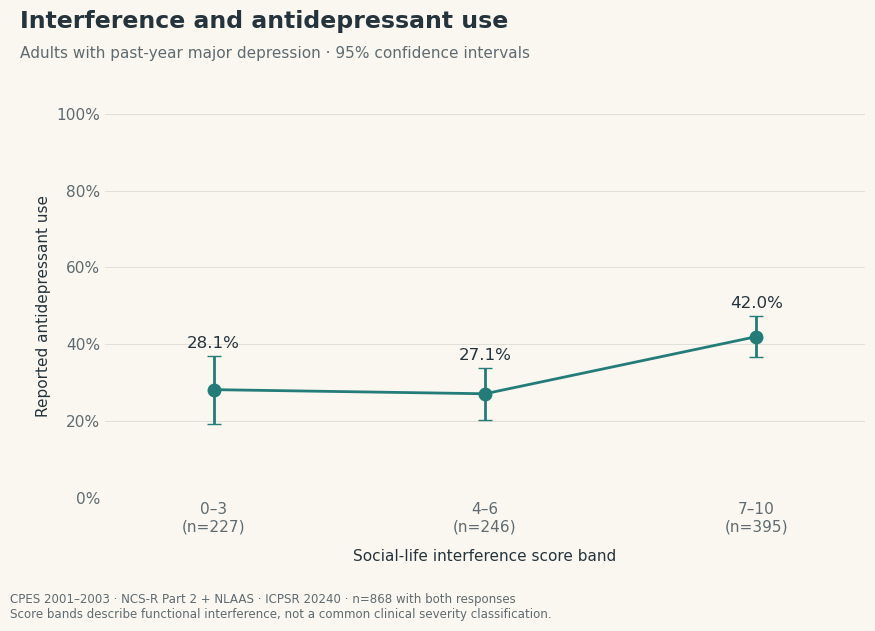

In [11]:
depression = cpes["V07655"].eq(1)
social = cpes["V00992"]
antidepressants = cpes["V02614"].map({1: 1., 5: 0.})
band_results = []
for lower, upper in [(0,3),(4,6),(7,10)]:
    result = survey_mean(cpes, antidepressants, depression & social.between(lower,upper), **CPES_DESIGN)
    band_results.append({"band": f"{lower}–{upper}", **result})
bands = pd.DataFrame(band_results)
assert bands["n"].tolist() == [227,246,395]
fig, ax = plt.subplots(figsize=(9.5, 6.5))
fig.subplots_adjust(left=.12,right=.92,bottom=.21,top=.80)
x=np.arange(3)
p=bands["estimate"].to_numpy()*100
low=bands["lower"].clip(0).to_numpy()*100
high=bands["upper"].clip(upper=1).to_numpy()*100
ax.errorbar(x,p,yerr=[p-low,high-p],color=TEAL,fmt="o-",ms=9,lw=2,capsize=5)
for xx,pp,hh in zip(x,p,high):
    ax.text(xx,hh+2,f"{pp:.1f}%",ha="center",fontsize=12)
ax.set_xticks(x,[f"{r.band}\n(n={r.n})" for r in bands.itertuples()])
ax.set_xlim(-.4,2.4)
ax.set_ylim(0,100)
ax.set_xlabel("Social-life interference score band",labelpad=10)
ax.set_ylabel("Reported antidepressant use")
percentage_axis(ax,"y")
clean_axis(ax,"y")
figure_title(fig,"Interference and antidepressant use", "Adults with past-year major depression · 95% confidence intervals")
finish_figure(fig,"08_interference_antidepressants.png",CPES_SOURCE + " · n=868 with both responses\nScore bands describe functional interference, not a common clinical severity classification.")


## Figure 09 · Interference and professional care

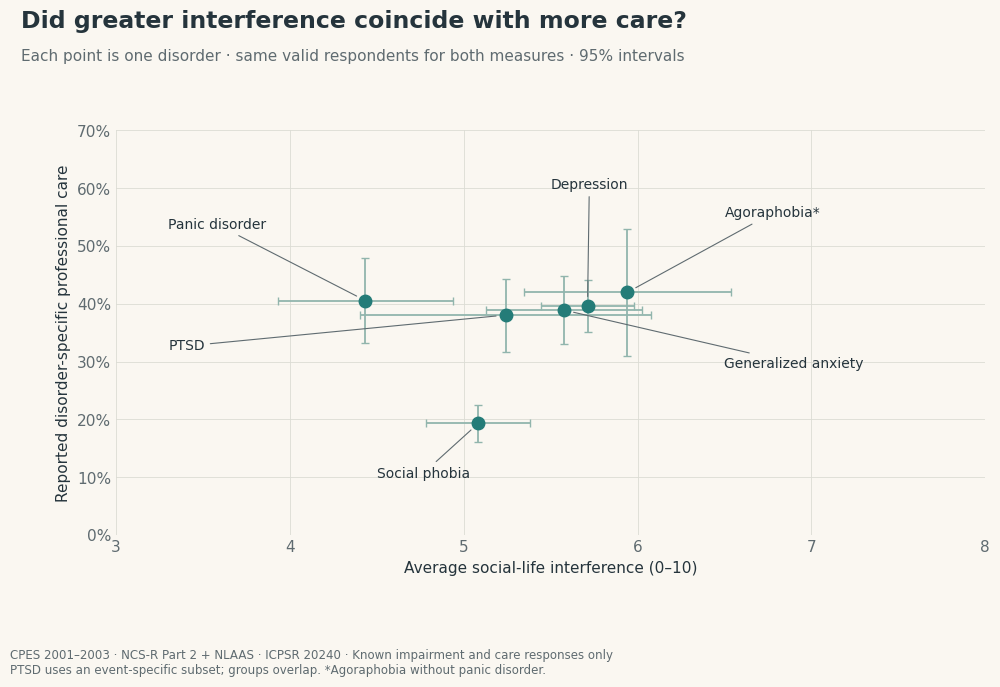

In [12]:
synthesis_rows = []
for label,(name,spec) in zip(DISORDER_LABELS,DISORDERS.items()):
    score=cpes[spec["social"]].where(cpes[spec["social"]].between(0,10))
    domain=cpes[spec["diagnosis"]].eq(1) & score.notna() & care_values[name].notna()
    burden=survey_mean(cpes,score,domain,**CPES_DESIGN)
    care=survey_mean(cpes,care_values[name],domain,**CPES_DESIGN)
    synthesis_rows.append({"label":label,"burden":burden,"care":care})
fig,ax=plt.subplots(figsize=(10.6,7.1))
fig.subplots_adjust(left=.12,right=.94,bottom=.22,top=.79)
label_positions=[(5.5,60),(6.5,29),(3.3,53),(4.5,10),(6.5,55),(3.3,32)]
for row,(label_x,label_y) in zip(synthesis_rows,label_positions):
    b,c=row["burden"],row["care"]
    ax.errorbar(b["estimate"],c["estimate"]*100,
                xerr=[[b["estimate"]-max(0,b["lower"])] ,[min(10,b["upper"])-b["estimate"]]],
                yerr=[[(c["estimate"]-max(0,c["lower"]))*100],[(min(1,c["upper"])-c["estimate"])*100]],
                fmt="o",color=TEAL,ecolor="#91B5AD",ms=9,capsize=3,lw=1.3)
    ax.annotate(row["label"],(b["estimate"],c["estimate"]*100),xytext=(label_x,label_y),
                ha="left",fontsize=10,color=INK,
                arrowprops={"arrowstyle":"-","color":MUTED,"lw":.8,"shrinkB":7})
ax.set_xlim(3,8)
ax.set_ylim(0,70)
ax.set_xlabel("Average social-life interference (0–10)")
ax.set_ylabel("Reported disorder-specific professional care")
percentage_axis(ax,"y")
clean_axis(ax)
ax.yaxis.grid(True,color=GRID,lw=.6)
figure_title(fig,"Did greater interference coincide with more care?", "Each point is one disorder · same valid respondents for both measures · 95% intervals")
finish_figure(fig,"09_burden_and_care.png",CPES_SOURCE + " · Known impairment and care responses only\nPTSD uses an event-specific subset; groups overlap. *Agoraphobia without panic disorder.")


## Figure 10 · Depression-related care in 2024

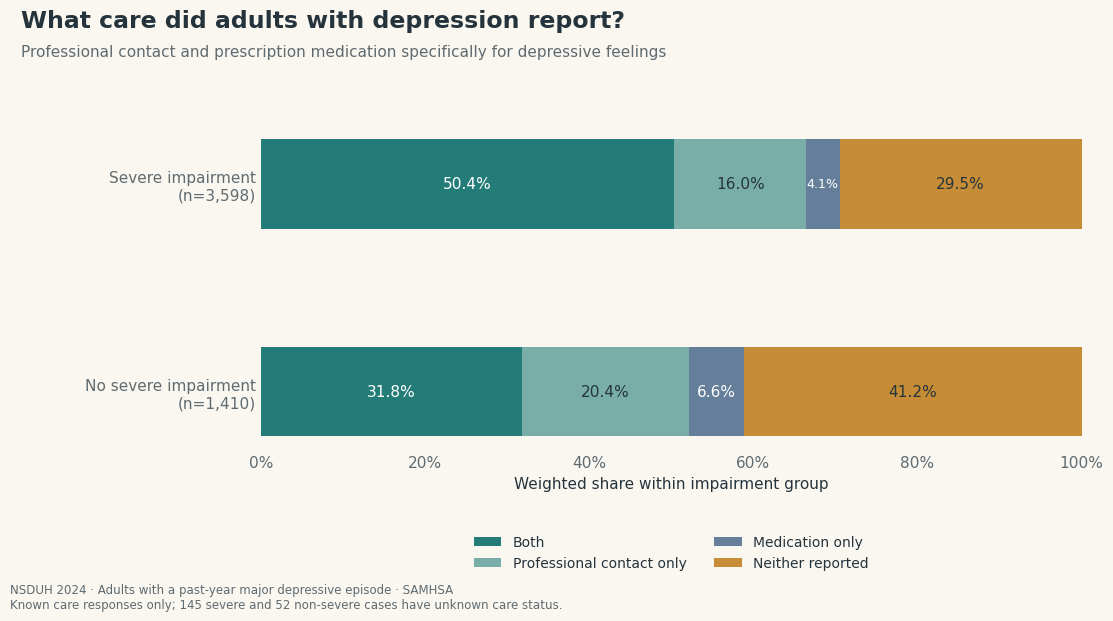

In [13]:
statuses=list(CARE_COLORS)
care_mix=[]
for code_value in [1,0]:
    group=nsduh_care["IRAMDEIMP"].eq(code_value)
    totals=nsduh_care.loc[group].groupby("care_group")["ANALWT2_C"].sum().reindex(statuses,fill_value=0)
    care_mix.append(totals/totals.sum()*100)
care_mix=np.asarray(care_mix)
assert np.allclose(care_mix.sum(axis=1),100)
fig,ax=plt.subplots(figsize=(11.4,6.4))
fig.subplots_adjust(left=.24,right=.96,bottom=.27,top=.78)
left=np.zeros(2)
for col,status in enumerate(statuses):
    values=care_mix[:,col]
    ax.barh([0,1],values,left=left,color=CARE_COLORS[status],height=.43,label=status)
    for row,value in enumerate(values):
        if value>=3:
            ax.text(left[row]+value/2,row,f"{value:.1f}%",ha="center",va="center",color="white" if status in ["Both","Medication only"] else INK,fontsize=11 if value>=6 else 9)
    left+=values
ax.set_yticks([0,1],["Severe impairment\n(n=3,598)","No severe impairment\n(n=1,410)"])
ax.invert_yaxis()
ax.set_xlim(0,100)
ax.set_xlabel("Weighted share within impairment group")
percentage_axis(ax)
ax.tick_params(length=0)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.22),ncol=2,frameon=False,fontsize=10)
figure_title(fig,"What care did adults with depression report?", "Professional contact and prescription medication specifically for depressive feelings")
finish_figure(fig,"10_depression_care_combinations.png",NSDUH_SOURCE + "\nKnown care responses only; 145 severe and 52 non-severe cases have unknown care status.")


## Figure 11 · Impairment, insurance, and care

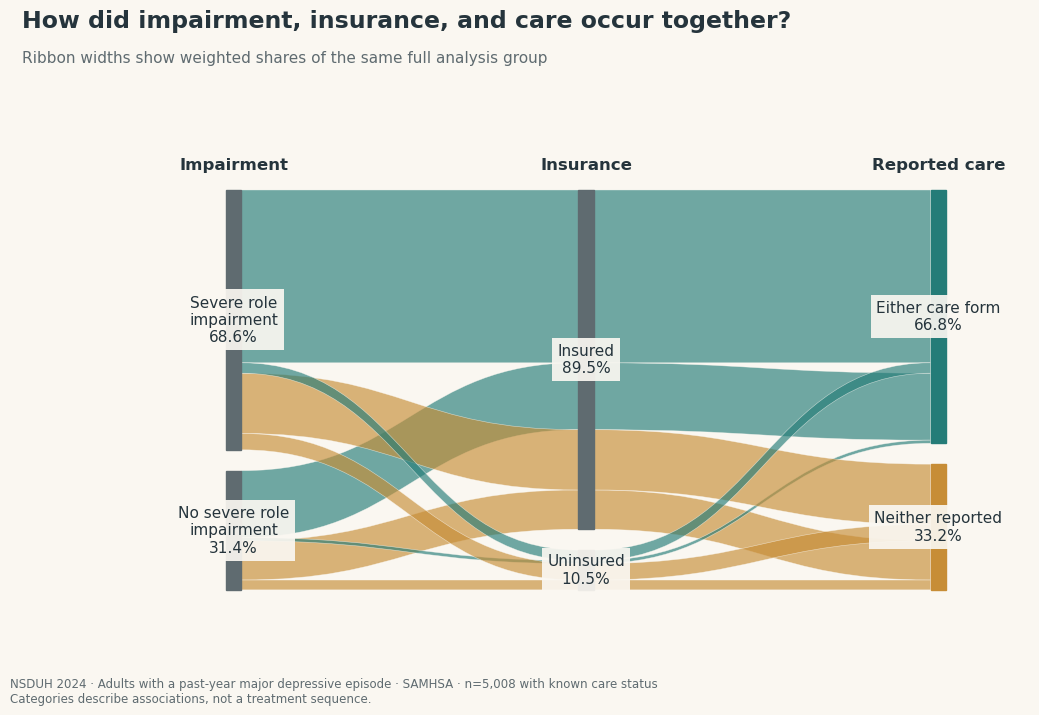

In [14]:
assert nsduh_care["IRAMDEIMP"].isin([0,1]).all() and nsduh_care["IRINSUR4"].isin([1,2]).all()
paths=nsduh_care.groupby(["IRAMDEIMP","IRINSUR4","reported_either"])["ANALWT2_C"].sum()
paths=paths/paths.sum()
assert np.isclose(paths.sum(),1) and len(paths)==8
stage_values=[[1,0],[1,2],[True,False]]
stage_labels=[["Severe role\nimpairment","No severe role\nimpairment"],["Insured","Uninsured"],["Either care form","Neither reported"]]
nodes,slots={},{}
gap=.055
for stage,values in enumerate(stage_values):
    cursor=1+gap
    for value in values:
        members=[p for p in paths.index if p[stage]==value]
        total=sum(paths[p] for p in members)
        top,bottom=cursor,cursor-total
        nodes[stage,value]=(bottom,top,total)
        offset=top
        for p in sorted(members,key=lambda p:(not p[2], -p[0], p[1])):
            slots[stage,p]=(offset-paths[p],offset)
            offset-=paths[p]
        assert np.isclose(offset,bottom)
        cursor=bottom-gap
fig,ax=plt.subplots(figsize=(12,7.4))
fig.subplots_adjust(left=.13,right=.87,bottom=.15,top=.78)
xs=[0,.5,1]
width=.022
def ribbon(x0,x1,lo0,hi0,lo1,hi1,color):
    control=(x1-x0)*.48
    vertices=[(x0,lo0),(x0+control,lo0),(x1-control,lo1),(x1,lo1),
              (x1,hi1),(x1-control,hi1),(x0+control,hi0),(x0,hi0),(x0,lo0)]
    commands=[MplPath.MOVETO,MplPath.CURVE4,MplPath.CURVE4,MplPath.CURVE4,
              MplPath.LINETO,MplPath.CURVE4,MplPath.CURVE4,MplPath.CURVE4,MplPath.CLOSEPOLY]
    ax.add_patch(PathPatch(MplPath(vertices,commands),facecolor=color,edgecolor=BG,lw=.4,alpha=.65))
for p,value in paths.items():
    color=TEAL if p[2] else GOLD
    for stage in [0,1]:
        lo0,hi0=slots[stage,p]
        lo1,hi1=slots[stage+1,p]
        assert np.isclose(hi0-lo0,value) and np.isclose(hi1-lo1,value)
        ribbon(xs[stage]+width/2,xs[stage+1]-width/2,lo0,hi0,lo1,hi1,color)
for stage,values in enumerate(stage_values):
    for value,label in zip(values,stage_labels[stage]):
        bottom,top,total=nodes[stage,value]
        color=(TEAL if value else GOLD) if stage==2 else MUTED
        ax.add_patch(Rectangle((xs[stage]-width/2,bottom),width,top-bottom,color=color,zorder=3))
        ax.text(xs[stage],(bottom+top)/2,f"{label}\n{total*100:.1f}%",ha="center",va="center",fontsize=11,zorder=4,
                bbox={"facecolor":BG,"edgecolor":"none","alpha":.92,"pad":4})
    ax.text(xs[stage],1.11,["Impairment","Insurance","Reported care"][stage],ha="center",weight="bold",fontsize=12)
ax.set_xlim(-.13,1.13)
ax.set_ylim(-.05,1.18)
ax.axis("off")
figure_title(fig,"How did impairment, insurance, and care occur together?", "Ribbon widths show weighted shares of the same full analysis group")
finish_figure(fig,"11_impairment_insurance_care_alluvial.png",NSDUH_SOURCE + " · n=5,008 with known care status\nCategories describe associations, not a treatment sequence.")


## Figure 12 · Insurance and reported care

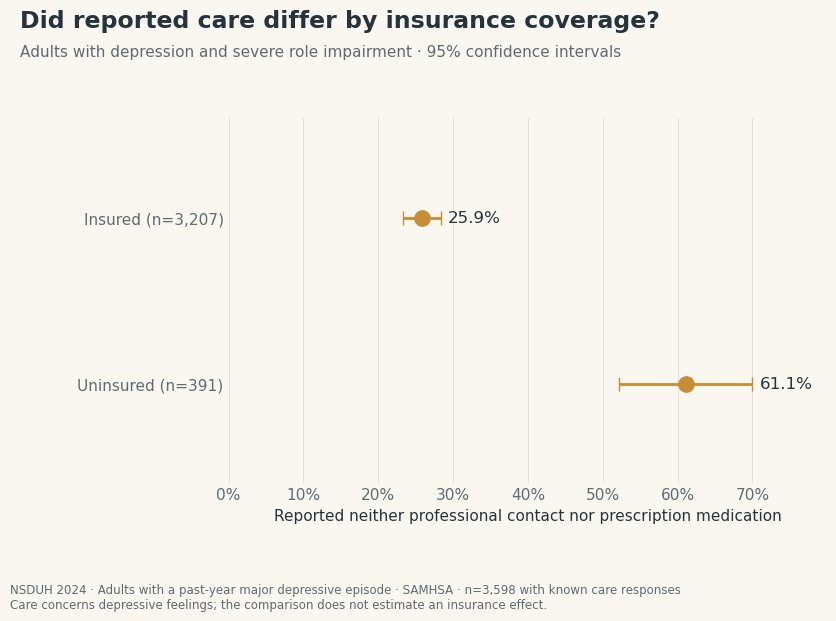

In [15]:
known = nsduh_raw["ATXMDEYR"].isin([0,1]) & nsduh_raw["ARXMDEYR"].isin([0,1])
neither = (nsduh_raw["ATXMDEYR"].eq(0) & nsduh_raw["ARXMDEYR"].eq(0)).astype(float).where(known)
severe = nsduh_raw["IRAMDEYR"].eq(1) & nsduh_raw["IRAMDEIMP"].eq(1)
insurance_rows=[]
for insurance_code,label in [(1,"Insured"),(2,"Uninsured")]:
    result=survey_mean(nsduh_raw,neither,severe & nsduh_raw["IRINSUR4"].eq(insurance_code),**NSDUH_DESIGN)
    insurance_rows.append({"label":label,**result})
insurance_rates=pd.DataFrame(insurance_rows)
assert insurance_rates["n"].tolist()==[3207,391]
fig,ax=plt.subplots(figsize=(9.5,6.4))
fig.subplots_adjust(left=.25,right=.88,bottom=.22,top=.79)
p=insurance_rates["estimate"].to_numpy()*100
low=insurance_rates["lower"].clip(0).to_numpy()*100
high=insurance_rates["upper"].clip(upper=1).to_numpy()*100
ax.errorbar(p,[0,1],xerr=[p-low,high-p],fmt="o",color=GOLD,ms=11,lw=2,capsize=5)
for yy,pp,hh in zip([0,1],p,high):
    ax.text(hh+1,yy,f"{pp:.1f}%",va="center",fontsize=12)
ax.set_yticks([0,1],[f"{r.label} (n={r.n:,})" for r in insurance_rates.itertuples()])
ax.invert_yaxis()
ax.set_ylim(1.6,-.6)
ax.set_xlim(0,max(60,high.max()+10))
ax.set_xlabel("Reported neither professional contact nor prescription medication")
percentage_axis(ax)
clean_axis(ax)
figure_title(fig,"Did reported care differ by insurance coverage?", "Adults with depression and severe role impairment · 95% confidence intervals")
finish_figure(fig,"12_insurance_care_comparison.png",NSDUH_SOURCE + " · n=3,598 with known care responses\nCare concerns depressive feelings; the comparison does not estimate an insurance effect.")


## Figure 13 · Care out of 100

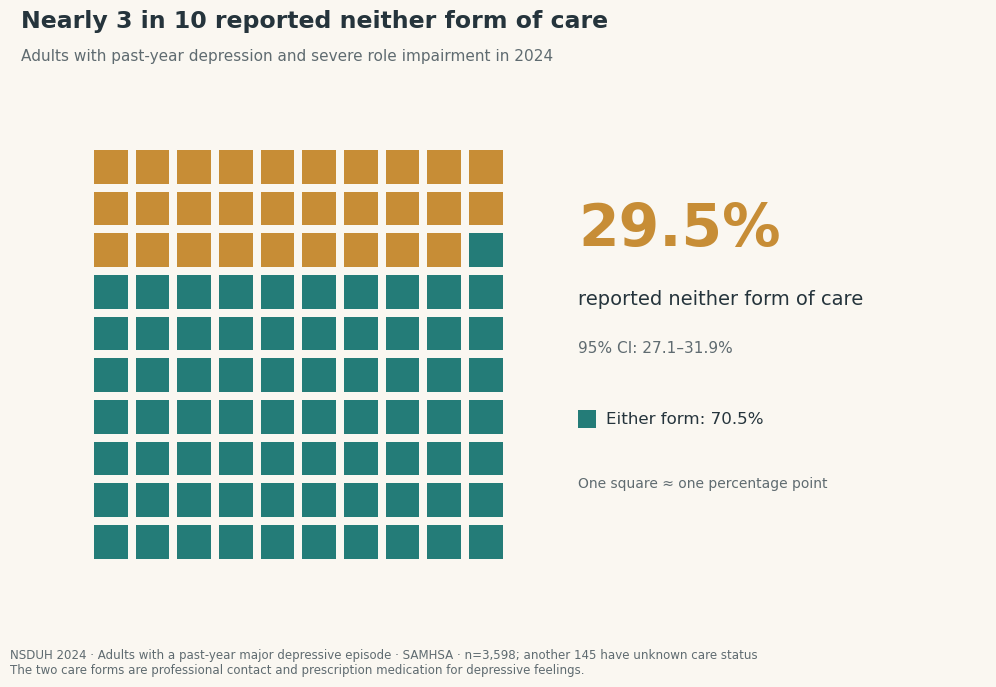

In [16]:
closing=survey_mean(nsduh_raw,neither,severe,**NSDUH_DESIGN)
no_care_pct=closing["estimate"]*100
rounded=int(np.floor(no_care_pct+.5))
unknown_severe=int((severe & ~known).sum())
assert closing["n"]==3598 and unknown_severe==145
fig,ax=plt.subplots(figsize=(10.7,7.1))
fig.subplots_adjust(left=.06,right=.96,bottom=.17,top=.79)
for i in range(100):
    row,col=divmod(i,10)
    ax.add_patch(Rectangle((col*.105,(9-row)*.105),.085,.085,facecolor=GOLD if i<rounded else TEAL,edgecolor="none"))
ax.text(1.22,.83,f"{no_care_pct:.1f}%",fontsize=42,weight="bold",color=GOLD,va="center")
ax.text(1.22,.64,"reported neither form of care",fontsize=14,color=INK)
ax.text(1.22,.52,f"95% CI: {max(0,closing['lower'])*100:.1f}–{min(1,closing['upper'])*100:.1f}%",fontsize=11,color=MUTED)
ax.add_patch(Rectangle((1.22,.33),.045,.045,facecolor=TEAL))
ax.text(1.29,.352,f"Either form: {100-no_care_pct:.1f}%",va="center",fontsize=12)
ax.text(1.22,.18,"One square ≈ one percentage point",fontsize=10,color=MUTED)
ax.set_xlim(-.03,2.25)
ax.set_ylim(-.03,1.08)
ax.set_aspect("equal")
ax.axis("off")
figure_title(fig,"Nearly 3 in 10 reported neither form of care", "Adults with past-year depression and severe role impairment in 2024")
finish_figure(fig,"13_care_out_of_100_waffle.png",NSDUH_SOURCE + " · n=3,598; another 145 have unknown care status\nThe two care forms are professional contact and prescription medication for depressive feelings.")
